In [1]:
from pathlib import Path
import string
import numpy as np
import pandas as pd
import rasterio as rio
from matplotlib import pyplot as plt

plt.rcParams['font.family'] = 'Arial'   # manuscript house font

In [2]:
# ---------------------------------------------------------------------------
# CONFIG — paths + the two scenarios this figure compares.
# ---------------------------------------------------------------------------
ROOT    = Path('..')
DATA    = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'

RES      = '50km'
DR       = 'DM-RM'    # central demand/reserve case
AR       = 'M'
BETA_BAU = 0.00       # BAU  = scenario BAU at beta 0.00
BETA_CON = 0.60       # CON  = scenario BAU at beta 0.60 (conservation-siting knee)

def asr_tif(beta):
    return RESULTS / 'biodiversity-risk' / f'mining-biodiversity-overlap-2050-BAU-B{beta:.2f}-{RES}-{DR}-A{AR}.tif'

COUNTRY_RASTER = RESULTS / 'country-rasters' / f'country-raster-eck4-{RES}.tif'

In [3]:
# --- country lookup table + country raster ------------------------------
country_pseudo_values = pd.read_csv(DATA / 'country-pseudo-values.csv')
country_raster_50km_  = rio.open(COUNTRY_RASTER)
country_raster_50km   = country_raster_50km_.read(1)

In [4]:
# --- rasters: BAU vs CON (= BAU at beta 0.60) ----------------------------
mining_biodiversity_overlap_BAU = rio.open(asr_tif(BETA_BAU)).read(1)
mining_biodiversity_overlap_CON = rio.open(asr_tif(BETA_CON)).read(1)

overlap_change_CON = mining_biodiversity_overlap_BAU - mining_biodiversity_overlap_CON

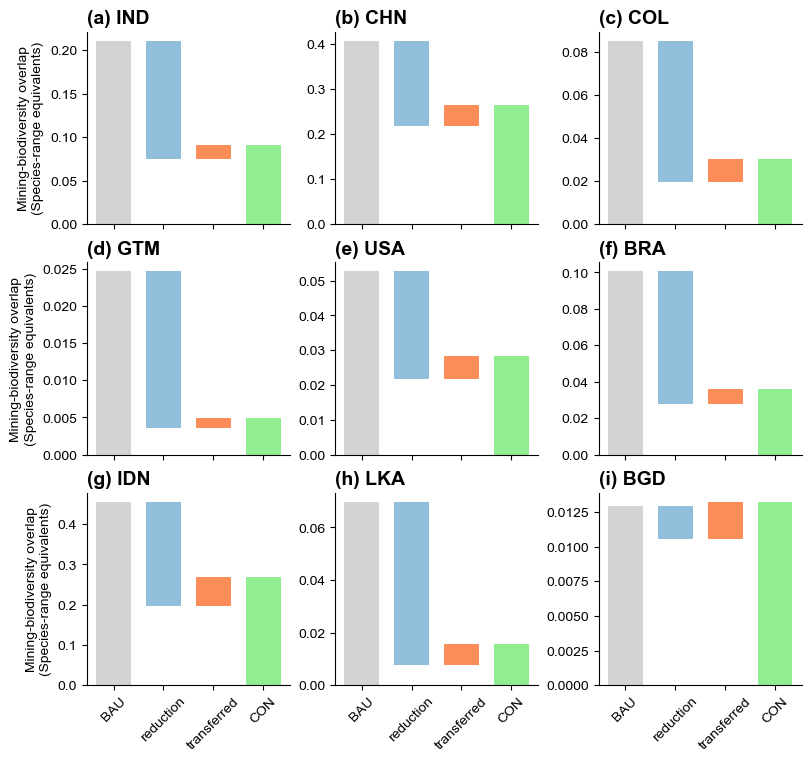

In [7]:
# ===================== Supplementary Figure 23: per-country waterfalls =====
def draw_waterfall_for_country(country, axx):
    country_code = country_pseudo_values[country_pseudo_values['country'] == country]['value'].values[0]
    total_BAU   = np.sum(np.where(country_raster_50km == country_code, mining_biodiversity_overlap_BAU, 0))
    total_CON   = np.sum(np.where(country_raster_50km == country_code, mining_biodiversity_overlap_CON, 0))
    ASR_change  = np.where(country_raster_50km == country_code, overlap_change_CON, 0)
    reduction   = np.sum(np.where(ASR_change > 0.000, ASR_change, 0))
    increase    = -np.sum(np.where(ASR_change < 0.000, ASR_change, 0))
    w = 0.7
    axx.bar(0, total_BAU, color='lightgrey', width=w)
    axx.bar(1, reduction, bottom=total_BAU - reduction, color='#91bfdb', width=w)
    axx.bar(2, increase, bottom=total_CON - increase, color='#fc8d59', width=w)
    axx.bar(3, total_CON, color='lightgreen', width=w)
    axx.set_ylabel('Mining-biodiversity overlap\n(Species-range equivalents)')
    axx.set_xticks([0, 1, 2, 3]); axx.set_xticklabels(['BAU', 'reduction', 'transferred', 'CON'], rotation=45)
    axx.spines['top'].set_visible(False); axx.spines['right'].set_visible(False)
    return axx

fig = plt.figure(figsize=(8, 7.5), constrained_layout=True)
for i, country in enumerate(['IND', 'CHN', 'COL', 'GTM', 'USA', 'BRA', 'IDN', 'LKA', 'BGD']):
    axx = plt.subplot(3, 3, i+1)
    draw_waterfall_for_country(country, axx)
    axx.set_title(f'({string.ascii_lowercase[i]}) {country}', size=14, loc='left', weight='bold')
    if (i % 3) != 0:
        axx.set_ylabel('')
    if i < 6:
        axx.set_xticklabels([])

plt.show()
fig.savefig(FIGURES / 'Supplementary-Figure-23.jpg', dpi=600, bbox_inches='tight')